# Data-Driven Social Engagement Initiative

End-to-end Colab workflow: synthetic data → data quality → engagement/viral metrics → EDA → sentiment/relatability → model → A/B-style analysis → recommendations → trend signals → Streamlit dashboard.

**Important:** All bundled records are synthetic. Do not present them as actual platform results.

In [6]:
import zipfile
import os

zip_path = "/content/Data_Driven_Social_Engagement_Initiative_GitHub_Ready.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/")

print("Project extracted successfully!")

Project extracted successfully!


In [7]:
import os

PROJECT_DIR = "/content/Data_Driven_Social_Engagement_Initiative"

for root, dirs, files in os.walk(PROJECT_DIR):
    print(root, files)

/content/Data_Driven_Social_Engagement_Initiative ['requirements.txt', 'Social_Engagement_Analytics_Colab.ipynb', 'app.py', '.gitignore', 'README.md']
/content/Data_Driven_Social_Engagement_Initiative/models ['README.txt']
/content/Data_Driven_Social_Engagement_Initiative/data ['social_posts.csv', 'comments.csv', 'hashtag_trends.csv']
/content/Data_Driven_Social_Engagement_Initiative/src ['data_collection_notes.md', 'sentiment.py', 'metrics.py', 'ab_testing.py', 'model.py']
/content/Data_Driven_Social_Engagement_Initiative/outputs ['README.txt']


In [8]:
from pathlib import Path

PROJECT_DIR = Path("/content/Data_Driven_Social_Engagement_Initiative")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

print("Project exists:", PROJECT_DIR.exists())
print("Dataset files:", list(DATA_DIR.iterdir()))

Project exists: True
Dataset files: [PosixPath('/content/Data_Driven_Social_Engagement_Initiative/data/social_posts.csv'), PosixPath('/content/Data_Driven_Social_Engagement_Initiative/data/comments.csv'), PosixPath('/content/Data_Driven_Social_Engagement_Initiative/data/hashtag_trends.csv')]


In [9]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn plotly scipy joblib streamlit pyngrok

## 1. Upload or load the project data


In [5]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, os, zipfile
from pathlib import Path
# If running from the extracted project folder, set PROJECT_DIR accordingly.
PROJECT_DIR = Path('/content/Data_Driven_Social_Engagement_Initiative')
if not PROJECT_DIR.exists():
    PROJECT_DIR = Path('/content')
DATA_DIR = PROJECT_DIR/'data'
posts = pd.read_csv(DATA_DIR/'social_posts.csv', parse_dates=['date'])
comments = pd.read_csv(DATA_DIR/'comments.csv')
trends = pd.read_csv(DATA_DIR/'hashtag_trends.csv', parse_dates=['date'])
print(posts.shape, comments.shape, trends.shape)
posts.head()

(1200, 13) (2200, 5) (900, 3)


,post_id,date,topic,content_format,hook_type,caption_length,reach,likes,comments,shares,saves,retention_rate,followers_gained
0,P0001,2025-04-01,Friendship,Static Image,Text,Medium,25828,651,368,408,507,34.8,134
1,P0002,2025-05-29,Burnout,Carousel,Story,Medium,12371,624,170,54,398,34.4,60
2,P0003,2025-03-07,Career Stress,Short Video,Story,Medium,26847,1509,379,120,287,52.2,70
3,P0004,2025-03-26,Dating,Long Video,Story,Medium,2752,68,19,14,42,43.9,14
4,P0005,2025-03-26,Friendship,Carousel,Story,Long,11930,770,47,73,35,38.5,24


## 2. Data quality checks

In [10]:
print(posts.isna().sum())
print('Duplicate post IDs:', posts.post_id.duplicated().sum())
posts = posts.drop_duplicates('post_id').copy()
posts = posts[(posts.reach > 0) & (posts[['likes','comments','shares','saves']] >= 0).all(axis=1)]
print('Clean shape:', posts.shape)

post_id             0
date                0
topic               0
content_format      0
hook_type           0
caption_length      0
reach               0
likes               0
comments            0
shares              0
saves               0
retention_rate      0
followers_gained    0
dtype: int64
Duplicate post IDs: 0
Clean shape: (1200, 13)


## 3. Engagement and viral coefficient proxy

In [11]:
posts['engagements'] = posts[['likes','comments','shares','saves']].sum(axis=1)
posts['engagement_rate'] = posts.engagements / posts.reach * 100
posts['share_rate'] = posts.shares / posts.reach * 100
posts['save_rate'] = posts.saves / posts.reach * 100
posts['save_to_share_ratio'] = posts.saves / posts.shares.replace(0, np.nan)
posts['viral_coefficient'] = (2*posts.shares + 2*posts.saves + posts.comments) / posts.reach
viral_threshold = posts.viral_coefficient.quantile(.80)
posts['high_viral_potential'] = (posts.viral_coefficient >= viral_threshold).astype(int)
print('Viral proxy threshold:', viral_threshold)
posts[['post_id','engagement_rate','viral_coefficient','high_viral_potential']].head()

Viral proxy threshold: 0.1036018640290507


,post_id,engagement_rate,viral_coefficient,high_viral_potential
0,P0001,7.487998,0.085101,0
1,P0002,10.071942,0.086816,0
2,P0003,8.548441,0.044437,0
3,P0004,5.196221,0.047602,0
4,P0005,7.753562,0.022045,0


## 4. Exploratory data analysis

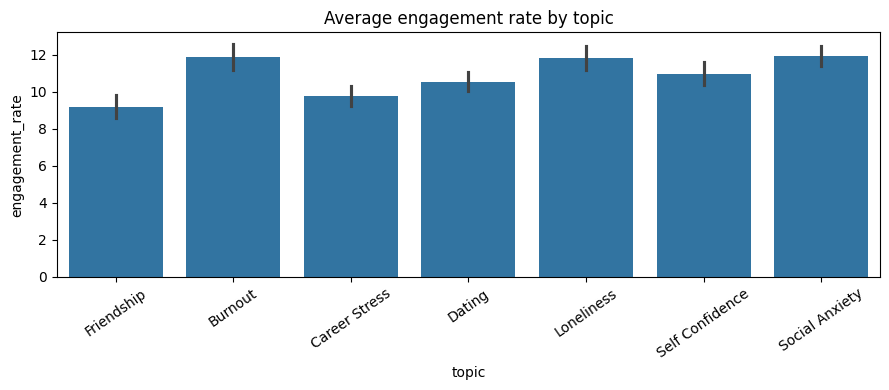

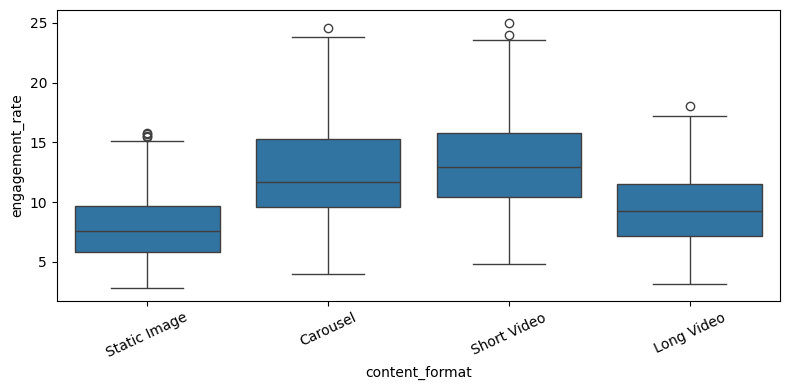

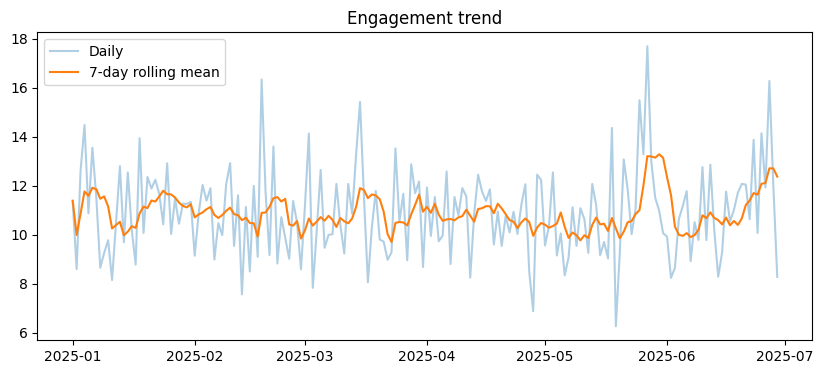

In [12]:
fig, ax = plt.subplots(figsize=(9,4)); sns.barplot(data=posts,x='topic',y='engagement_rate',estimator='mean',ax=ax); ax.tick_params(axis='x',rotation=35); ax.set_title('Average engagement rate by topic'); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(8,4)); sns.boxplot(data=posts,x='content_format',y='engagement_rate',ax=ax); ax.tick_params(axis='x',rotation=25); plt.tight_layout(); plt.show()
daily=posts.groupby('date',as_index=False).engagement_rate.mean()
daily['rolling_7d']=daily.engagement_rate.rolling(7,min_periods=1).mean()
plt.figure(figsize=(10,4)); plt.plot(daily.date,daily.engagement_rate,alpha=.35,label='Daily'); plt.plot(daily.date,daily.rolling_7d,label='7-day rolling mean'); plt.legend(); plt.title('Engagement trend'); plt.show()

## 5. Audience sentiment and relatability baseline

In [13]:
import re
POS={'seen','only','needed','relatable','thank','understood','feel','helpful','same','exactly'}
NEG={'not','never','disagree','irrelevant','wrong','unhelpful'}
def label_comment(t):
    w=set(re.findall(r"[a-z']+",str(t).lower())); s=len(w&POS)-len(w&NEG)
    sentiment='Positive' if s>0 else ('Negative' if s<0 else 'Neutral')
    relatable='Relatable' if (w & {'seen','only','relatable','understood','same','needed'}) else 'Neutral'
    return pd.Series([sentiment,relatable])
comments[['predicted_sentiment','relatability']]=comments.comment_text.apply(label_comment)
print(comments.predicted_sentiment.value_counts())
print(comments.relatability.value_counts())
comments.head()

predicted_sentiment
Positive    1048
Neutral      879
Negative     273
Name: count, dtype: int64
relatability
Neutral      1347
Relatable     853
Name: count, dtype: int64


,comment_id,post_id,topic,comment_text,synthetic_sentiment,predicted_sentiment,relatability
0,C00001,P0475,Dating,I do not agree with this,Negative,Negative,Neutral
1,C00002,P0708,Dating,Thanks for sharing,Neutral,Neutral,Neutral
2,C00003,P0138,Loneliness,Thank you for explaining this,Positive,Positive,Neutral
3,C00004,P0856,Loneliness,Needed to hear this today,Positive,Positive,Relatable
4,C00005,P0713,Career Stress,Thank you for explaining this,Positive,Positive,Neutral


## 6. Virality prediction model

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import joblib
features=['topic','content_format','hook_type','caption_length','reach','retention_rate','likes','comments','shares','saves']
cat=['topic','content_format','hook_type','caption_length']; num=[c for c in features if c not in cat]
pre=ColumnTransformer([('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('ohe',OneHotEncoder(handle_unknown='ignore'))]),cat),('num',Pipeline([('imp',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num)])
model=Pipeline([('pre',pre),('rf',RandomForestClassifier(n_estimators=250,max_depth=10,class_weight='balanced',random_state=42))])
Xtr,Xte,ytr,yte=train_test_split(posts[features],posts.high_viral_potential,test_size=.2,random_state=42,stratify=posts.high_viral_potential)
model.fit(Xtr,ytr); pred=model.predict(Xte); prob=model.predict_proba(Xte)[:,1]
print(classification_report(yte,pred)); print('ROC-AUC:',roc_auc_score(yte,prob)); print(confusion_matrix(yte,pred))
(PROJECT_DIR/'models').mkdir(exist_ok=True); joblib.dump(model,PROJECT_DIR/'models/viral_potential_model.joblib')

              precision    recall  f1-score   support

           0       0.87      0.99      0.92       192
           1       0.90      0.40      0.55        48

    accuracy                           0.87       240
   macro avg       0.89      0.69      0.74       240
weighted avg       0.88      0.87      0.85       240

ROC-AUC: 0.9335937499999999
[[190   2]
 [ 29  19]]


['/content/Data_Driven_Social_Engagement_Initiative/models/viral_potential_model.joblib']

## 7. A/B-style statistical comparisons

In [15]:
from scipy.stats import mannwhitneyu
pairs=[]
for metric in ['engagement_rate','share_rate','save_rate','retention_rate']:
    groups=list(posts.groupby('content_format')[metric])
    for i in range(len(groups)):
        for j in range(i+1,len(groups)):
            stat,p=mannwhitneyu(groups[i][1],groups[j][1],alternative='two-sided')
            pairs.append({'metric':metric,'format_a':groups[i][0],'format_b':groups[j][0],'p_value':p})
ab_results=pd.DataFrame(pairs); ab_results.head(10)

,metric,format_a,format_b,p_value
0,engagement_rate,Carousel,Long Video,4.033892e-19
1,engagement_rate,Carousel,Short Video,6.354773e-03
2,engagement_rate,Carousel,Static Image,9.750407e-43
3,engagement_rate,Long Video,Short Video,1.310759e-30
4,engagement_rate,Long Video,Static Image,6.605506e-10
5,engagement_rate,Short Video,Static Image,3.885714e-55
6,share_rate,Carousel,Long Video,6.513993e-08
7,share_rate,Carousel,Short Video,7.018952e-01
8,share_rate,Carousel,Static Image,7.213275e-14
9,share_rate,Long Video,Short Video,8.616891e-09


**Interpretation caution:** These are observational comparisons of simulated groups, not randomized A/B experiments. P-values do not establish that a format caused higher engagement.

## 8. Engagement optimization recommender

In [16]:
recommendations=posts.groupby(['topic','content_format','hook_type']).agg(posts=('post_id','count'),mean_engagement=('engagement_rate','mean'),mean_save_rate=('save_rate','mean'),mean_share_rate=('share_rate','mean')).reset_index()
recommendations=recommendations[recommendations.posts>=5].sort_values(['mean_engagement','mean_save_rate'],ascending=False)
recommendations.head(15)

,topic,content_format,hook_type,posts,mean_engagement,mean_save_rate,mean_share_rate
10,Burnout,Short Video,Text,12,15.907321,2.528386,1.626081
105,Social Anxiety,Short Video,Story,16,15.511492,2.323014,2.513185
0,Burnout,Carousel,Question,9,15.382228,2.067962,2.179931
89,Self Confidence,Short Video,Story,14,15.233751,2.583292,1.944071
91,Self Confidence,Short Video,Visual,6,14.912132,3.064267,1.688093
74,Loneliness,Short Video,Text,10,14.729481,3.040749,1.458905
3,Burnout,Carousel,Visual,8,14.707509,1.990760,2.194623
8,Burnout,Short Video,Question,11,14.366147,2.187802,2.257553
66,Loneliness,Carousel,Text,9,14.351511,1.698597,2.023486
73,Loneliness,Short Video,Story,11,14.335862,2.013785,1.934369


## 9. Hashtag trend signals

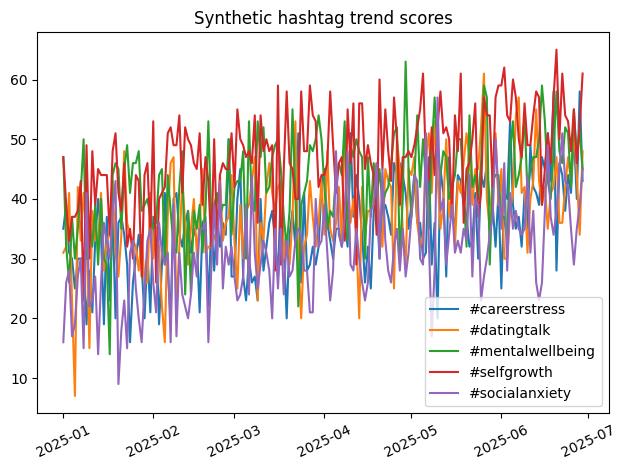

In [17]:
trend_summary=trends.groupby(['date','hashtag'],as_index=False).trend_score.mean()
for tag,g in trend_summary.groupby('hashtag'):
    plt.plot(g.date,g.trend_score,label=tag)
plt.legend(); plt.title('Synthetic hashtag trend scores'); plt.xticks(rotation=25); plt.tight_layout(); plt.show()

## 10. Export results

In [18]:
out=PROJECT_DIR/'outputs'; out.mkdir(exist_ok=True)
posts.to_csv(out/'posts_with_metrics.csv',index=False)
comments.to_csv(out/'comments_with_sentiment.csv',index=False)
ab_results.to_csv(out/'ab_comparisons.csv',index=False)
recommendations.to_csv(out/'content_recommendations.csv',index=False)
trend_summary.to_csv(out/'hashtag_trend_summary.csv',index=False)
print('Saved outputs to',out)

Saved outputs to /content/Data_Driven_Social_Engagement_Initiative/outputs


## 11. Launch Streamlit dashboard from Colab
Upload/extract the project folder, install Streamlit and pyngrok

In [19]:
!pip -q install streamlit pyngrok plotly
# For ngrok, add NGROK_AUTH_TOKEN to Colab Secrets, then:
from google.colab import userdata
from pyngrok import ngrok
import subprocess, time, os
try:
    token=userdata.get('NGROK_AUTH_TOKEN')
    ngrok.set_auth_token(token)
    tunnel=ngrok.connect(8501)
    print('Dashboard URL:', tunnel.public_url)
    proc=subprocess.Popen(['streamlit','run',str(PROJECT_DIR/'app.py'),'--server.port','8501','--server.address','0.0.0.0'])
except Exception as e:
    print('Set NGROK_AUTH_TOKEN in Colab Secrets, then rerun this cell. Error:',e)

Set NGROK_AUTH_TOKEN in Colab Secrets, then rerun this cell. Error: Secret NGROK_AUTH_TOKEN does not exist.


In [20]:
import os

PROJECT_DIR = "/content/Data_Driven_Social_Engagement_Initiative"

print("Project exists:", os.path.exists(PROJECT_DIR))
print("app.py exists:", os.path.exists(PROJECT_DIR + "/app.py"))

Project exists: True
app.py exists: True


In [21]:
!pip install -q streamlit pyngrok

In [22]:
import subprocess
import os

APP_PATH = "/content/Data_Driven_Social_Engagement_Initiative/app.py"

process = subprocess.Popen(
    [
        "streamlit", "run", APP_PATH,
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

print("Streamlit process ID:", process.pid)

Streamlit process ID: 1813


In [23]:
from pyngrok import ngrok
from getpass import getpass
import time

token = getpass("Enter your ngrok authentication token: ")

ngrok.set_auth_token(token)

time.sleep(5)

tunnel = ngrok.connect(8501, "http")

print("YOUR DASHBOARD URL:")
print(tunnel.public_url)

Enter your ngrok authentication token: ··········
YOUR DASHBOARD URL:
https://snort-boat-unpleased.ngrok-free.dev
